# A brush with Ceres: when the planets are not enough

**The question.** (613383) 2022 KX28 is an ordinary 1-2 km main-belt asteroid with eleven
apparitions of astrometry since 2006. Fitted with the Sun, planets and Moon alone, its orbit is
excellent on the 2013-2026 data (0.16") and *hopeless* on everything before: the 2006, 2010 and 2011
apparitions sit hundreds of arcseconds off, and the fit throws all 35 of those observations away.
Nothing is wrong with them. In January 2013 the asteroid passed about 38,000 km from (1) Ceres, deep
inside the dwarf planet's Hill sphere, and Ceres' gravity bent its orbit.

This notebook shows how PyRoOrb finds that out on its own. Every main-belt, multi-opposition fit
gets an **asteroid polish**: the orbit is re-fitted with JPL's 16 most massive asteroids as
perturbers (the `sb441-n16` kernel, `pyroorb-fetch-data --asteroids`, ~600 MB), the rejected
observations are re-judged, and the perturbed orbit is kept only when it fits the *same*
observations measurably better. Here it reclaims all three lost apparitions. We then measure the
encounter, check it against JPL, and estimate the kick by hand.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. The gravity-only fit

`fit_orbit` with the asteroid perturbers off (`pyroorb.asteroid_perturbers(False)`). The table lists, per apparition, how many observations the fit kept
and the median size of the residual (observed minus computed) under that orbit.

In [2]:
from astropy.time import Time

DESIG = "613383"                                  # (613383) 2022 KX28
obs = pyroorb.fetch_observations(DESIG)
pyroorb.asteroid_perturbers(False)                # planets only
grav = pyroorb.fit_orbit(obs, designation=DESIG)

def by_apparition(f):
    res = f.residuals()
    year = np.array([Time(r["jd_utc"], format="jd").decimalyear for r in res]).astype(int)
    used = np.array([r["included"] for r in res])
    size = np.hypot([r["d_ra_arcsec"] for r in res], [r["d_dec_arcsec"] for r in res])
    rows = [{"year": y, "obs": int((year == y).sum()), "used": int(used[year == y].sum()),
             "median |O-C| (arcsec)": round(float(np.median(size[year == y])), 2)}
            for y in sorted(set(year))]
    return pd.DataFrame(rows).set_index("year")

print(f"{grav.n_observations()} of {grav.n_total_observations()} obs used, rms {grav.rms_residual():.3f}\", "
      f"{grav.n_oppositions()} oppositions, a = {grav.elements()['a']:.3f} au, force model {grav.force_model}")
by_apparition(grav)

118 of 153 obs used, rms 0.161", 8 oppositions, a = 2.444 au, force model ASSIST(DE440+GR)


,obs,used,median |O-C| (arcsec)
year,,,
2006,18,0,494.11
2010,11,0,256.04
2011,6,0,43.93
2013,4,4,0.48
2014,29,29,0.12
2015,3,3,0.18
2021,16,16,0.14
2022,15,15,0.10
2023,15,15,0.17


The orbit that fits 2013-2026 to a tenth of an arcsecond misses 2011 by ~40", 2010 by ~250" and
2006 by ~500". Growing with distance in time from 2013, that is the signature of a change in the
orbit *at* 2013, not of bad astrometry.

## 2. The same observations, with the 16 asteroids

Fit again inside `pyroorb.asteroid_perturbers()`, with the 16 most massive asteroids perturbing
the orbit from the start. (The command line and the web interface reach the same orbit by
*polishing* every converged main-belt gravity fit with the perturbers -- 153 of 153 observations at
0.263" here too. They keep the perturbed orbit only when it lowers the rms on the **same**
observations, judged on both fits' sets: on the gravity fit's own set alone the test would be
circular, because gravity had already discarded exactly the apparitions only the perturbers fit.)

In [3]:
with pyroorb.asteroid_perturbers():               # the same observations, the 16 asteroids on
    ast = pyroorb.fit_orbit(obs, designation=DESIG)
print(f"{ast.n_observations()} of {ast.n_total_observations()} obs used, rms {ast.rms_residual():.3f}\", "
      f"force model {ast.force_model}")
by_apparition(ast)

153 of 153 obs used, rms 0.263", force model ASSIST(DE440+GR+16ast)


,obs,used,median |O-C| (arcsec)
year,,,
2006,18,18,0.35
2010,11,11,0.64
2011,6,6,0.37
2013,4,4,0.48
2014,29,29,0.12
2015,3,3,0.18
2021,16,16,0.14
2022,15,15,0.10
2023,15,15,0.18


With the 16 perturbers every apparition fits at the 0.1-0.3" level and all 153 observations are
kept. On the gravity fit's own 118 observations the two models are equal (the perturbation is
invisible after 2013); across the whole arc only the perturbed one fits.

## 3. Which perturber, and how close?

Propagate the perturbed orbit from 1995 to 2030 and measure its distance to each of the 16
perturbers, from the same ephemeris (`pyroorb.body_states`).

In [4]:
AU_KM = 1.495978707e8
T = lambda jd_tdb: Time(jd_tdb, format="jd", scale="tdb")     # TDB Julian dates as times
PERTURBERS = ["Ceres", "Pallas", "Juno", "Vesta", "Iris", "Hygiea", "Eunomia", "Psyche", "Euphrosyne",
              "Europa", "Cybele", "Sylvia", "Thisbe", "Camilla", "Davida", "Interamnia"]

t = Time("1995-01-01").tdb.jd + np.arange(0, 35 * 365.25, 1.0)
X = pyroorb.propagate(ast, T(t))[:, :3]          # in the model it was fitted in: the 16 asteroids on
rows = []
for name in PERTURBERS:
    d = np.linalg.norm(X - pyroorb.body_states(name, T(t))[:, :3], axis=1)
    k = d.argmin()
    rows.append({"perturber": name, "closest (au)": round(float(d[k]), 4),
                 "closest (million km)": round(float(d[k]) * AU_KM / 1e6, 2),
                 "date": T(t[k]).iso[:10]})
pd.DataFrame(rows).set_index("perturber").sort_values("closest (au)").head(6)

,closest (au),closest (million km),date
perturber,,,
Ceres,0.0007,0.11,2013-01-10
Eunomia,0.1660,24.83,2020-12-10
Vesta,0.1859,27.81,2018-09-29
Juno,0.3320,49.67,2002-02-24
Psyche,0.4254,63.64,1999-12-03
Pallas,0.5515,82.50,2007-12-05


One encounter stands out by two orders of magnitude: Ceres, in January 2013, at under
0.001 au. Now the encounter itself, with uncertainty. We draw 200 clones from the fit's covariance,
propagate them through the encounter on a 10-minute grid, and compare with JPL, whose Horizons
ephemerides for 2022 KX28 and for Ceres come from their own solutions and the same `sb441` masses.

In [5]:
import json, urllib.request, urllib.parse

GM_CERES, GM_SUN = 62.6284, 1.32712440018e11          # km^3/s^2 (Dawn; DE440)
window = ("2012-11-01", "2013-03-01")
ca = pyroorb.close_approaches(ast, *window, body="ceres", max_distance=0.01)[0]       # the nominal orbit
enc = pyroorb.sample_orbits(ast, 200, rng_seed=2013).close_approaches(*window, body="ceres", max_distance=0.01)[0]
ca_t = np.r_[ca["jd_tdb"], enc["jd_tdb"]]                       # nominal first, then 200 clones
ca_d = np.r_[ca["distance_au"], enc["distance_au"]] * AU_KM
v_rel = ca["v_rel_km_s"]
r_hill = np.linalg.norm(pyroorb.body_states("ceres", T(ca_t[0]))[0, :3]) * AU_KM * (GM_CERES / (3 * GM_SUN)) ** (1 / 3)
tf = ca_t[0] + np.arange(-2, 2, 10 / 1440)                      # +-2 d, 10-minute steps, for JPL

def horizons_vectors(cmd, jd0, jd1, step="10 m"):
    q = {"format": "json", "COMMAND": f"'{cmd};'", "EPHEM_TYPE": "VECTORS", "CENTER": "'500@10'",
         "START_TIME": f"'JD{jd0}'", "STOP_TIME": f"'JD{jd1}'", "STEP_SIZE": f"'{step}'",
         "VEC_TABLE": "2", "REF_PLANE": "FRAME", "OUT_UNITS": "AU-D", "CSV_FORMAT": "YES"}
    res = json.load(urllib.request.urlopen(
        "https://ssd.jpl.nasa.gov/api/horizons.api?" + urllib.parse.urlencode(q), timeout=60))["result"]
    rows = res.split("$$SOE")[1].split("$$EOE")[0].strip().splitlines()
    return np.array([[float(v) for v in r.split(",")[2:8]] for r in rows])

jk = horizons_vectors(DESIG, tf[0], tf[-1])[:len(tf)]
jc = horizons_vectors("1", tf[0], tf[-1])[:len(tf)]
jd_ = np.linalg.norm(jk[:, :3] - jc[:, :3], axis=1) * AU_KM
j = jd_.argmin()

print(f"{'':20s}{'PyRoOrb':>24s}{'JPL Horizons':>16s}")
print(f"{'closest approach':20s}{Time(ca_t[0], format='jd', scale='tdb').utc.iso[:16] + ' UTC':>24s}"
      f"{Time(tf[j], format='jd', scale='tdb').utc.iso[:16]:>16s}")
print(f"{'miss distance (km)':20s}{f'{ca_d[0]:,.0f} +/- {ca_d.std():,.0f}':>24s}{jd_[j]:>16,.0f}")
print(f"{'relative speed':20s}{f'{v_rel:.2f} km/s':>24s}")
print(f"\nCeres' Hill radius there: {r_hill:,.0f} km  ->  the encounter was at {ca_d[0] / r_hill:.2f} Hill radii")

                                     PyRoOrb    JPL Horizons
closest approach        2013-01-09 16:20 UTC2013-01-09 16:20
miss distance (km)             37,942 +/- 31          37,932
relative speed                     3.65 km/s

Ceres' Hill radius there: 214,224 km  ->  the encounter was at 0.18 Hill radii


PyRoOrb and JPL agree on the encounter to about 10 km, inside the clone cloud's 30 km spread,
and the asteroid went *through* Ceres' Hill sphere, where Ceres' gravity beats the Sun's tide,
at a fifth of its radius.

### The kick, by hand

In the impulse approximation a body passing a mass $GM$ at distance $b$ and speed $v$ picks up
$\Delta v = 2\,GM / (b\,v)$. A velocity change $\Delta v$ along the orbit builds up an along-track
displacement of about $3\,\Delta v\,t$ after time $t$. How far should the pre-encounter
apparitions be off, seen from Earth at a couple of au?

In [6]:
dv = 2 * GM_CERES / (ca_d[0] * v_rel)                      # km/s
print(f"impulse from Ceres: {dv * 1000:.2f} m/s")
for yr_before in (2, 3, 7):
    drift = 3 * dv * yr_before * 3.156e7                   # km
    print(f"  {yr_before} yr before the encounter: along-track drift ~{drift:,.0f} km"
          f" ~ {np.degrees(drift / (2 * AU_KM)) * 3600:,.0f} arcsec at 2 au")

impulse from Ceres: 0.91 m/s
  2 yr before the encounter: along-track drift ~171,382 km ~ 118 arcsec at 2 au
  3 yr before the encounter: along-track drift ~257,073 km ~ 177 arcsec at 2 au
  7 yr before the encounter: along-track drift ~599,838 km ~ 414 arcsec at 2 au


The order of magnitude matches the gravity-only table above: tens of arcseconds two years before
the encounter, hundreds of arcseconds three and seven years before. (The impulse approximation is
crude at a fifth of a Hill radius, and the geometry of each apparition changes the projected size,
so the numbers are not meant to match one for one.)

## 4. The residuals, apparition by apparition

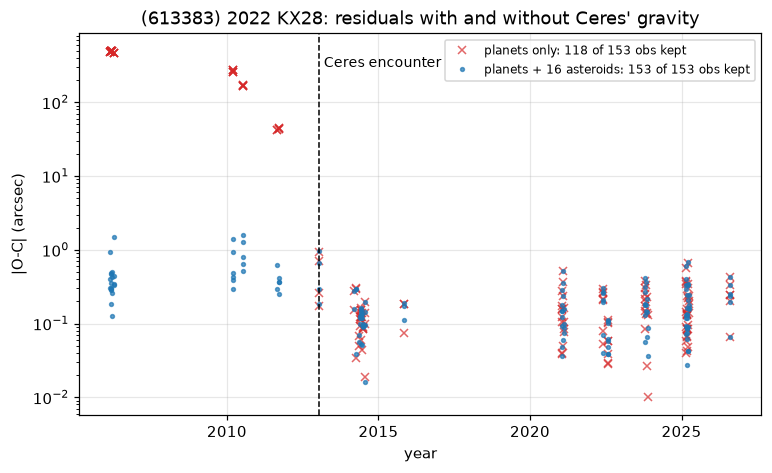

In [7]:
fig, ax = plt.subplots()
for f, label, marker, color in ((grav, "planets only", "x", "C3"), (ast, "planets + 16 asteroids", ".", "C0")):
    res = f.residuals()
    yr = np.array([Time(r["jd_utc"], format="jd").decimalyear for r in res])
    size = np.hypot([r["d_ra_arcsec"] for r in res], [r["d_dec_arcsec"] for r in res])
    ax.semilogy(yr, np.maximum(size, 0.01), marker, ms=5, alpha=0.7, color=color,
                label=f"{label}: {f.n_observations()} of {f.n_total_observations()} obs kept")
ax.axvline(Time(ca_t[0], format="jd", scale="tdb").decimalyear, color="k", ls="--", lw=1)
ax.text(2013.2, 300, "Ceres encounter", fontsize=9)
ax.set(xlabel="year", ylabel="|O-C| (arcsec)", title="(613383) 2022 KX28: residuals with and without Ceres' gravity")
ax.legend(loc="upper right", fontsize=8)
plt.show()

## Takeaways

* A main-belt orbit can be wrong by hundreds of arcseconds with a perfect 0.16" fit, when the
  fit has quietly discarded the apparitions that contradict its force model. Rejected observations
  that cluster by apparition are a force-model symptom, not a data symptom.
* PyRoOrb's asteroid polish catches this without being told: it tries the 16 perturbers on every
  main-belt, multi-opposition object and judges the two models on both observation sets.
* For 2022 KX28 the culprit is a single pass through Ceres' Hill sphere in January 2013, which
  PyRoOrb places within about 10 km of JPL's ephemerides.

**Caveats.** The 16-perturber kernel is JPL's; PyRoOrb adds nothing to the masses. Fitting with
the perturbers from the start (`PYROORB_ASTEROIDS_PATH`, notebook 02) gives the same orbit; the
polish exists so that the default, faster gravity fit is still checked. Encounters with the ~300
smaller asteroids JPL also integrates are not modelled.